# Are Drivers Dodging the Congestion Toll?
**Data with Mehreen · Week 2: Timing the toll**

In Week 1 we saw entries jump **53% between 3am and 4am**, right before weekday peak pricing starts. Is that toll-dodging, or just the normal morning rush starting?

### How the toll works
- **Peak toll** (about \$9 for a car with E-ZPass): **5am–9pm on weekdays**, **9am–9pm on weekends**
- **Overnight toll:** 75% cheaper (about \$2.25)
- **Taxis and Uber/Lyft** don't pay by time of day. They pay a small charge **per trip**, the same at any hour.

### The trick: a built-in experiment 🧪
1. **Two different start times.** Peak starts at **5am on weekdays** but **9am on weekends**. If drivers are dodging, the rush just before the toll should **move with the schedule**: before 5am on weekdays and before 9am on weekends.
2. **A control group.** Taxis/Uber/Lyft have no reason to time their trips around the toll. If private cars spike right before peak and taxis don't, the toll is the likely reason.

### Questions for Week 2
1. Does the hourly pattern differ between weekdays and weekends, around each one's peak start?
2. Do private cars rush in just before peak more than taxis do?
3. Zooming into 10-minute blocks: is there a spike at 4:50am and a drop at 5:00am?
4. What happens at 9pm, when the toll drops again?
5. Is the effect growing or fading from 2025 to 2026?

## 1. Setup

In [1]:
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
API_URL = "https://data.ny.gov/resource/t6yz-b64h.json"

CAR, TAXI = "Cars/Pickups/Vans", "Taxi / Uber / Lyft"
CAR_COLOR, TAXI_COLOR = "#1f4e79", "#8e44ad"
VEHICLE_LABELS = {
    "1 - Cars, Pickups and Vans": CAR,
    "2 - Single-Unit Trucks": "Single-unit trucks",
    "3 - Multi-Unit Trucks": "Multi-unit trucks",
    "4 - Buses": "Buses",
    "5 - Motorcycles": "Motorcycles",
    "TLC Taxi/FHV": TAXI,
}

## 2. Get the data
Same helper as Week 1. Results are cached in `data/`, so the API is only called once.

In [2]:
def fetch_soql(select, group, order, name, where=None, page_size=50_000):
    """Run an aggregated SoQL query (with paging) and cache the result as CSV."""
    cache = DATA_DIR / f"{name}.csv"
    if cache.exists():
        print(f"Loaded cached {cache}")
        return pd.read_csv(cache)

    rows, offset = [], 0
    while True:
        params = {"$select": select, "$group": group, "$order": order,
                  "$limit": page_size, "$offset": offset}
        if where:
            params["$where"] = where
        r = requests.get(API_URL, params=params, timeout=180)
        r.raise_for_status()
        batch = r.json()
        rows.extend(batch)
        print(f"  {name}: fetched {len(rows):,} rows")
        if len(batch) < page_size:
            break
        offset += page_size

    df = pd.DataFrame(rows)
    df.to_csv(cache, index=False)
    return df

| Table | Grouped by | Approx. rows | Used for |
|---|---|---|---|
| `daily_hourly` | date × hour × vehicle class | ~100,000 | weekday vs weekend, trends by month |
| `ten_minute` | year × day of week × hour × 10-min block × vehicle class | ~12,000 | zooming in on the minutes around 5am, 9am and 9pm |

The first table is the biggest yet, so the download may take a minute or two.

In [3]:
daily_hourly = fetch_soql(
    select="toll_date, hour_of_day, vehicle_class, sum(crz_entries) AS entries",
    group="toll_date, hour_of_day, vehicle_class",
    order="toll_date, hour_of_day, vehicle_class",
    name="daily_hourly",
)

ten_minute = fetch_soql(
    select=("date_extract_y(toll_date) AS year, day_of_week_int, hour_of_day, "
            "minute_of_hour, vehicle_class, sum(crz_entries) AS entries"),
    group="date_extract_y(toll_date), day_of_week_int, hour_of_day, minute_of_hour, vehicle_class",
    order="year, day_of_week_int, hour_of_day, minute_of_hour, vehicle_class",
    name="ten_minute",
)
daily_hourly.head()

Loaded cached data/daily_hourly.csv
Loaded cached data/ten_minute.csv


,toll_date,hour_of_day,vehicle_class,entries
0,2025-01-05T00:00:00.000,0,"1 - Cars, Pickups and Vans",6554
1,2025-01-05T00:00:00.000,0,2 - Single-Unit Trucks,137
2,2025-01-05T00:00:00.000,0,3 - Multi-Unit Trucks,23
3,2025-01-05T00:00:00.000,0,4 - Buses,106
4,2025-01-05T00:00:00.000,0,5 - Motorcycles,42


## 3. Clean
- Same cleaning as Week 1, and drop the last incomplete week
- Add **weekday vs weekend** and **minutes since midnight** (handy for 10-minute charts)
- Remove the **storm days** found in Week 1, so they don't distort the averages
- Holidays follow a weekend-style pattern, so we drop the main federal holidays from the weekday group

In [4]:
daily_hourly["toll_date"] = pd.to_datetime(daily_hourly["toll_date"]).dt.tz_localize(None)
for col in ["hour_of_day", "entries"]:
    daily_hourly[col] = pd.to_numeric(daily_hourly[col])
daily_hourly["vehicle"] = daily_hourly["vehicle_class"].map(VEHICLE_LABELS).fillna(daily_hourly["vehicle_class"])

# Keep complete weeks only (weeks run Sunday to Saturday)
last_date = daily_hourly["toll_date"].max()
cutoff = last_date - pd.Timedelta(days=(last_date.dayofweek - 5) % 7)
daily_hourly = daily_hourly[daily_hourly["toll_date"] <= cutoff]

# Remove storm and travel-ban days (see Week 1)
STORM_DAYS = pd.to_datetime(["2026-01-25", "2026-01-26", "2026-02-22", "2026-02-23", "2026-02-24"])
daily_hourly = daily_hourly[~daily_hourly["toll_date"].isin(STORM_DAYS)]

# Weekday / weekend, with federal holidays treated separately
from pandas.tseries.holiday import USFederalHolidayCalendar
holidays = USFederalHolidayCalendar().holidays(start="2025-01-01", end="2026-12-31")
is_weekend = daily_hourly["toll_date"].dt.dayofweek >= 5
is_holiday = daily_hourly["toll_date"].isin(holidays)
daily_hourly["day_type"] = np.select([is_holiday, is_weekend], ["Holiday", "Weekend"], "Weekday")
daily_hourly["year"] = daily_hourly["toll_date"].dt.year

print("Date range:", daily_hourly["toll_date"].min().date(), "to", cutoff.date())
print(daily_hourly.groupby("day_type")["toll_date"].nunique().rename("days"))

Date range: 2025-01-05 to 2026-11-14
day_type
Holiday     19
Weekday    463
Weekend    192
Name: days, dtype: int64


In [5]:
for col in ["year", "day_of_week_int", "hour_of_day", "minute_of_hour", "entries"]:
    ten_minute[col] = pd.to_numeric(ten_minute[col])

# How many calendar days fall in each (year, day of week)? Needed to turn totals into per-day averages.
all_days = pd.DataFrame({"date": pd.date_range("2025-01-05", last_date)})
all_days["year"] = all_days["date"].dt.year
all_days["day_of_week_int"] = (all_days["date"].dt.dayofweek + 1) % 7 + 1   # Sunday = 1 ... Saturday = 7
n_days = all_days.groupby(["year", "day_of_week_int"]).size().rename("n_days").reset_index()
ten_minute = ten_minute.merge(n_days, on=["year", "day_of_week_int"], how="left")
ten_minute["vehicle"] = ten_minute["vehicle_class"].map(VEHICLE_LABELS).fillna(ten_minute["vehicle_class"])
# day_of_week_int: 1 = Sunday ... 7 = Saturday
ten_minute["day_type"] = np.where(ten_minute["day_of_week_int"].isin([1, 7]), "Weekend", "Weekday")
ten_minute["minute_of_day"] = ten_minute["hour_of_day"] * 60 + ten_minute["minute_of_hour"]
# Note: this table includes every day (storms and holidays too), and the newest partial week.
# Averages over ~95 weeks are barely affected, but keep it in mind.
ten_minute.head()

,year,day_of_week_int,hour_of_day,minute_of_hour,vehicle_class,entries,n_days,vehicle,day_type,minute_of_day
0,2025,1,0,0,"1 - Cars, Pickups and Vans",69255,52,Cars/Pickups/Vans,Weekend,0
1,2025,1,0,0,2 - Single-Unit Trucks,1357,52,Single-unit trucks,Weekend,0
2,2025,1,0,0,3 - Multi-Unit Trucks,170,52,Multi-unit trucks,Weekend,0
3,2025,1,0,0,4 - Buses,1275,52,Buses,Weekend,0
4,2025,1,0,0,5 - Motorcycles,413,52,Motorcycles,Weekend,0


## 4. Analysis
### Q1: Does the pattern move with the toll schedule?
We plot each hour's **share of the day's entries**, separately for weekdays and weekends. Shares make the two comparable, even though weekdays are busier.

**What to look for:** a bump in the hour **just before** each one's peak start (4am on weekdays, 8am on weekends).

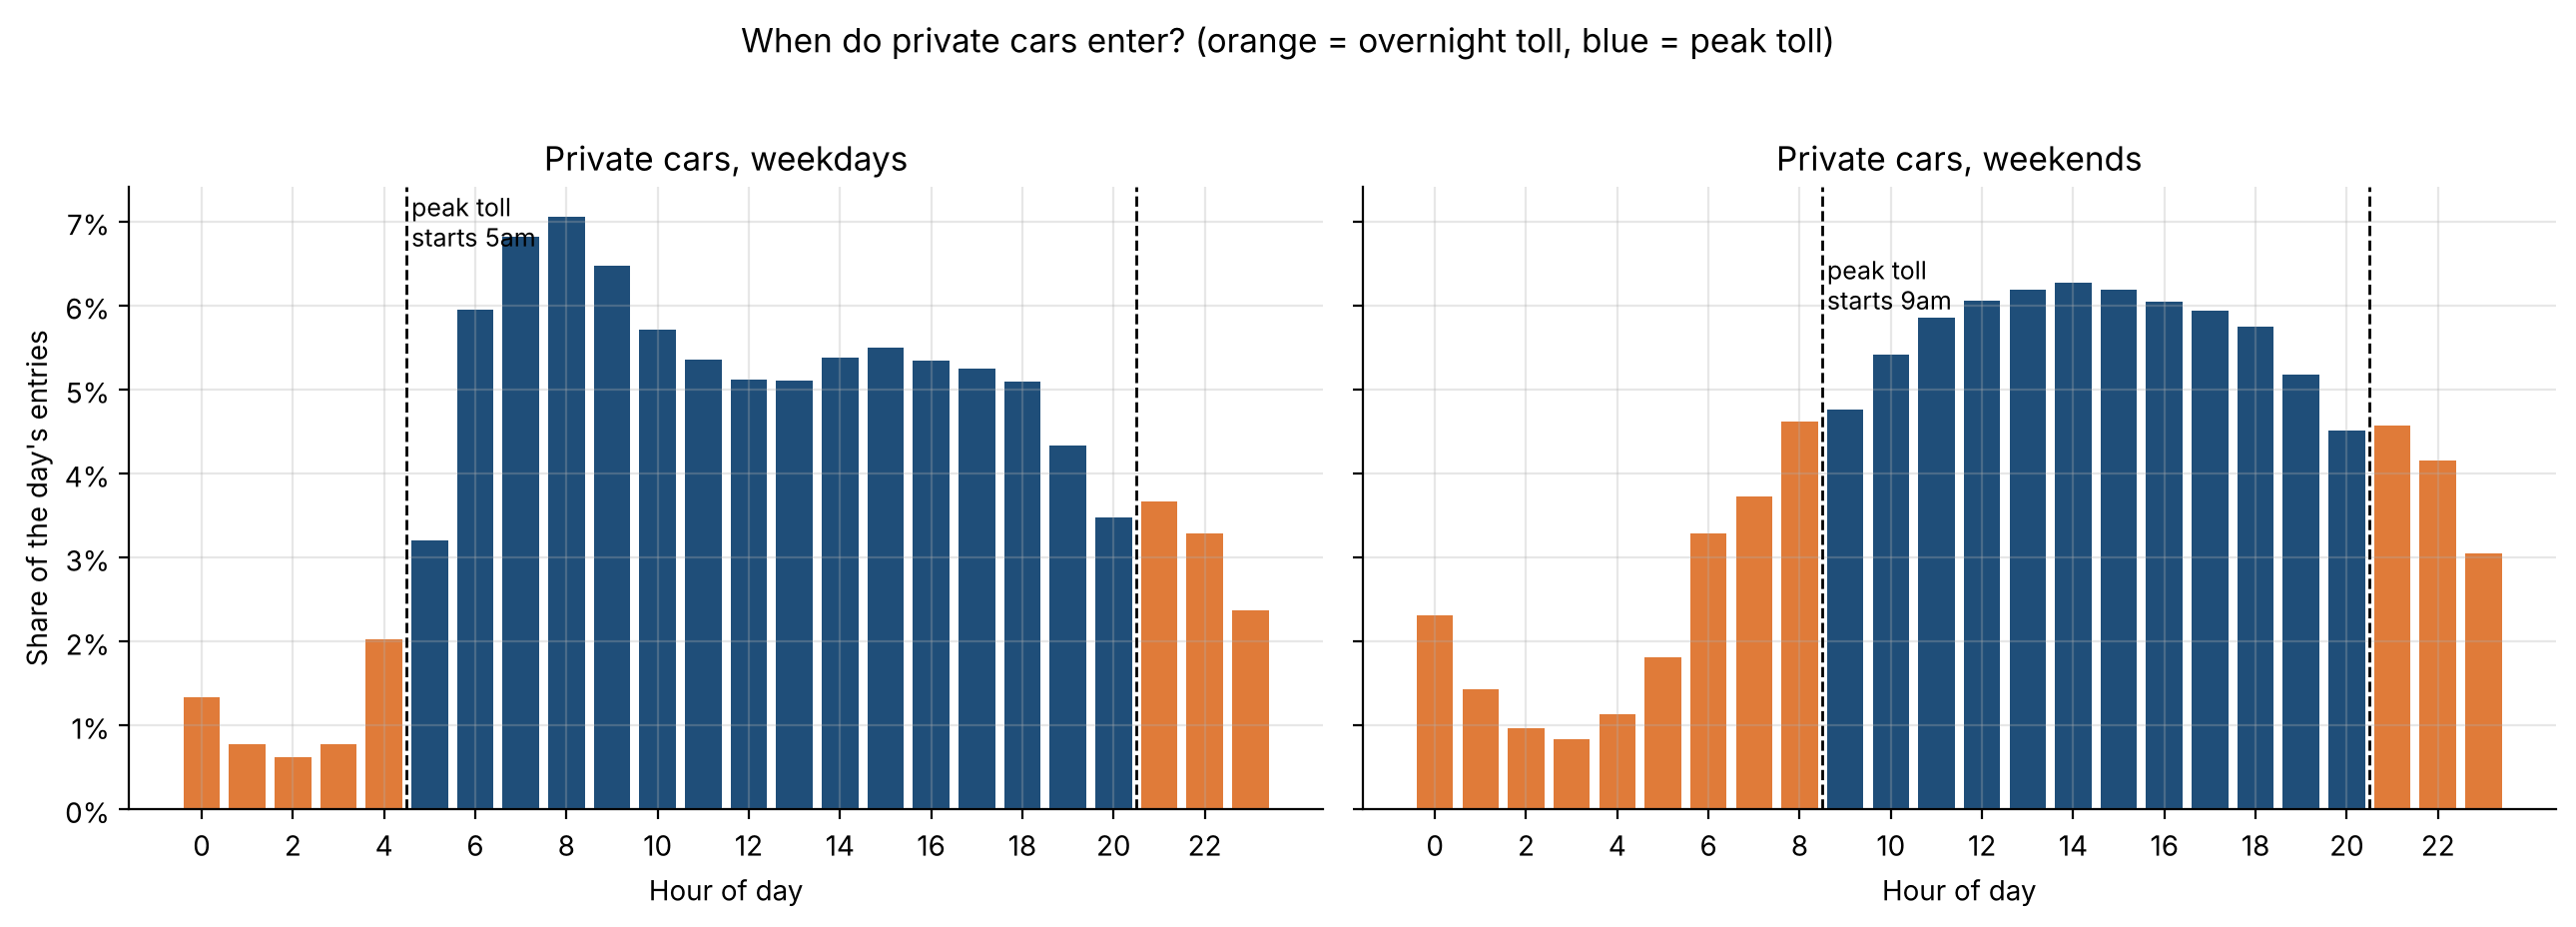

In [6]:
def hourly_share(df, vehicle, day_type):
    sub = df[(df["vehicle"] == vehicle) & (df["day_type"] == day_type)]
    by_hour = sub.groupby("hour_of_day")["entries"].sum()
    return by_hour / by_hour.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, day_type, peak_start in zip(axes, ["Weekday", "Weekend"], [5, 9]):
    share = hourly_share(daily_hourly, CAR, day_type)
    colors = ["#e07b39" if (h < peak_start or h >= 21) else CAR_COLOR for h in share.index]
    ax.bar(share.index, share.values, color=colors)
    ax.axvline(peak_start - 0.5, color="black", ls="--", lw=1)
    ax.text(peak_start - 0.4, share.max() * 0.95, f"peak toll\nstarts {peak_start}am", fontsize=9)
    ax.axvline(20.5, color="black", ls="--", lw=1)
    ax.set_title(f"Private cars, {day_type.lower()}s")
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_ylabel("Share of the day's entries")
fig.suptitle("When do private cars enter? (orange = overnight toll, blue = peak toll)", y=1.02)
plt.tight_layout(); plt.show()

### Q2: Cars vs. taxis, our control group
Taxis/Uber/Lyft pay the same per trip at any hour, so they have no reason to rush before peak.

We divide **car entries by taxi entries** for every hour. If cars are dodging the toll, the car-to-taxi ratio should **spike just before peak starts** and **jump right after it ends**.

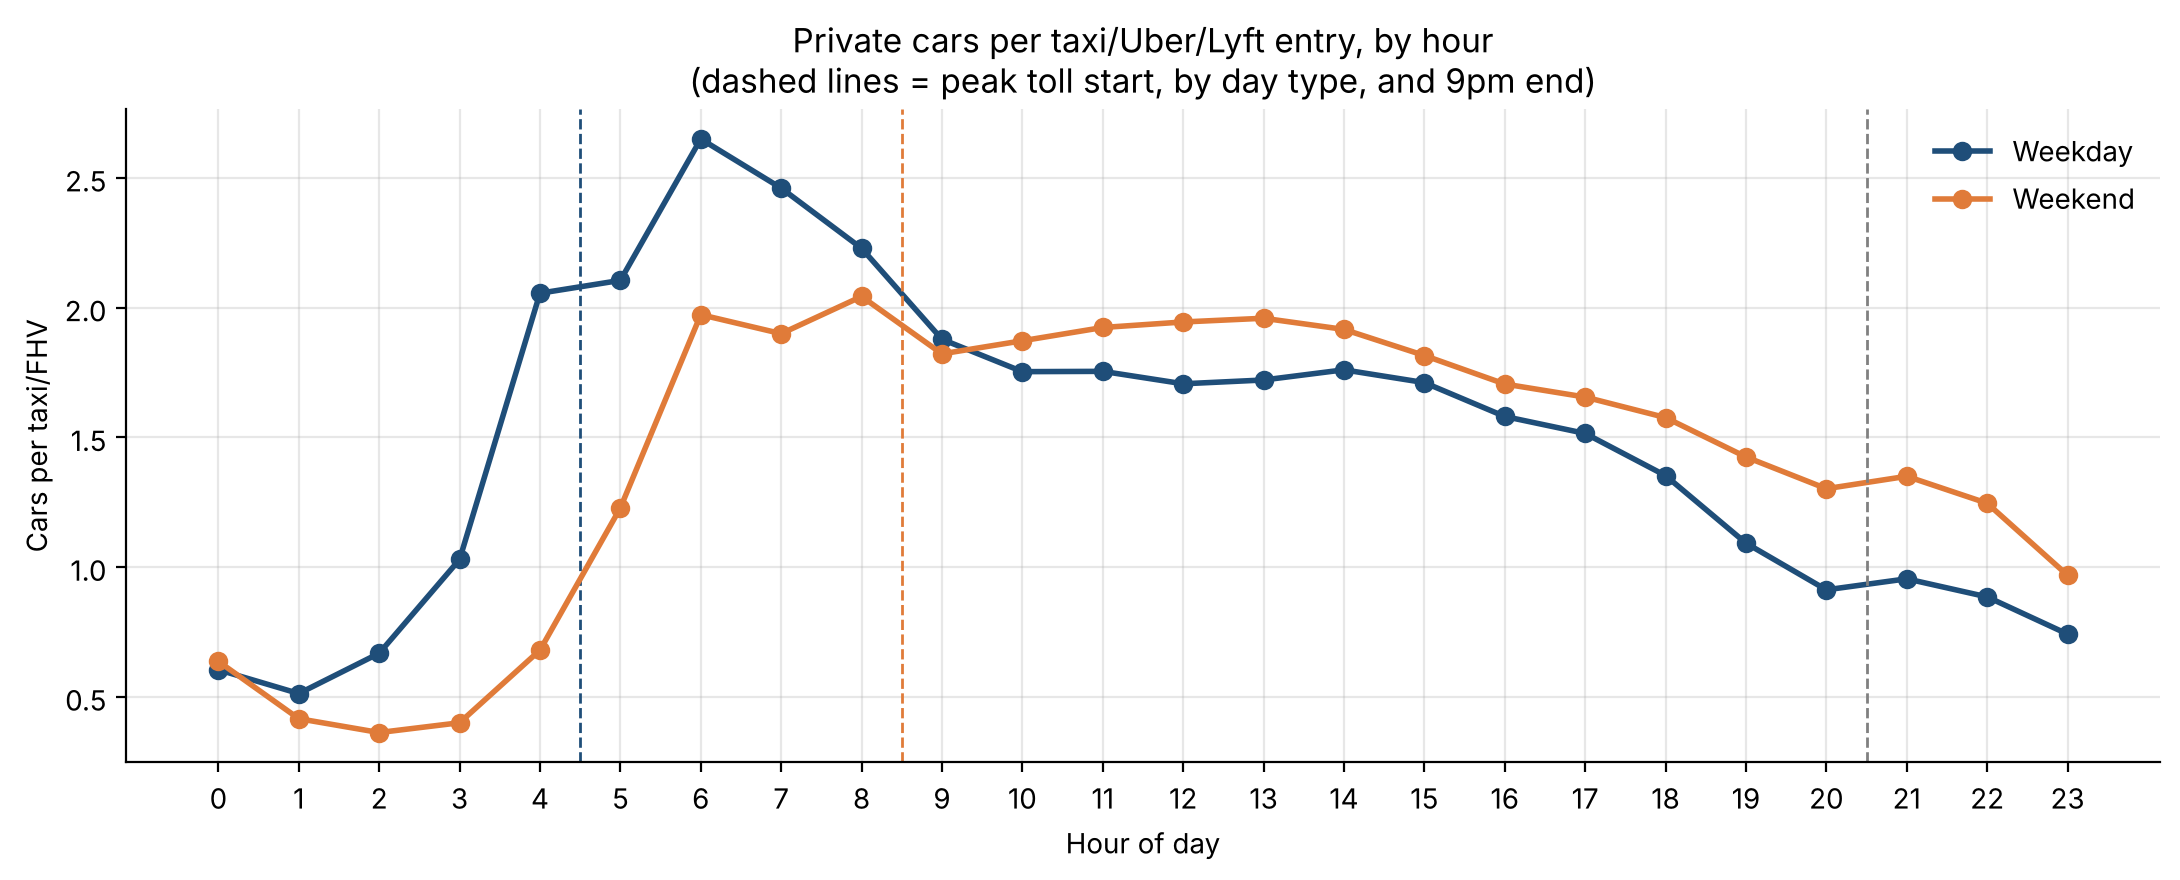

In [7]:
def car_taxi_ratio(df, day_type):
    sub = df[df["day_type"] == day_type]
    pivot = sub.pivot_table(index="hour_of_day", columns="vehicle", values="entries", aggfunc="sum")
    return pivot[CAR] / pivot[TAXI]

fig, ax = plt.subplots()
for day_type, color, peak_start in [("Weekday", CAR_COLOR, 5), ("Weekend", "#e07b39", 9)]:
    ratio = car_taxi_ratio(daily_hourly, day_type)
    ax.plot(ratio.index, ratio.values, marker="o", lw=2, color=color, label=day_type)
    ax.axvline(peak_start - 0.5, color=color, ls="--", lw=1)
ax.axvline(20.5, color="gray", ls="--", lw=1)
ax.set_xticks(range(24))
ax.set_title("Private cars per taxi/Uber/Lyft entry, by hour\n(dashed lines = peak toll start, by day type, and 9pm end)")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Cars per taxi/FHV")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Q3: Zoom in on the minutes around peak start
Hourly data can hide the effect. With **10-minute blocks** we can see what happens right at 5:00am (weekdays) and 9:00am (weekends).

Both lines are **indexed to 100** at the start of the window, so cars and taxis can be compared on the same scale.

**What to look for:** cars rising faster than taxis until the last block before peak, then **dropping** at peak start.

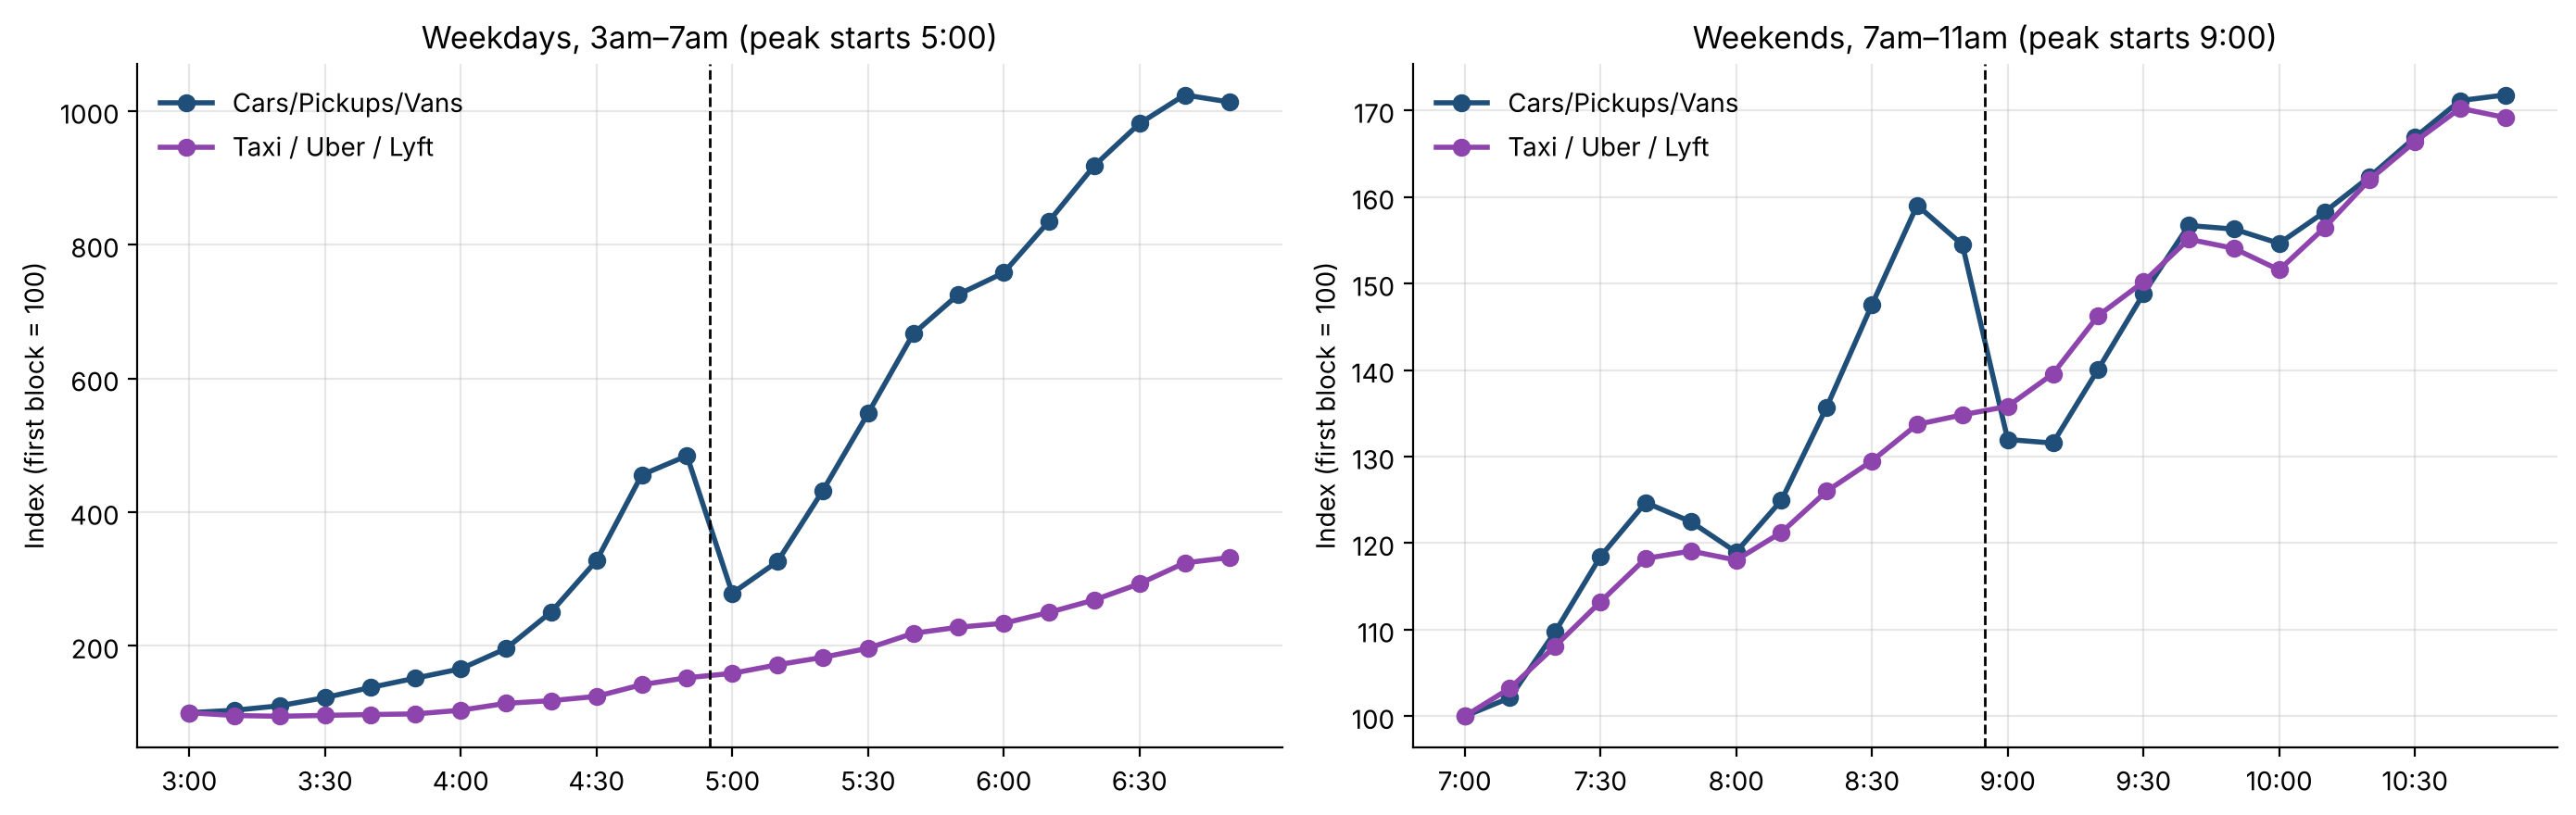

In [8]:
def ten_min_profile(df, day_type, vehicle, start_hour, end_hour):
    sub = df[(df["day_type"] == day_type) & (df["vehicle"] == vehicle)
             & df["hour_of_day"].between(start_hour, end_hour)]
    # average entries per day in each 10-minute block
    totals = sub.groupby("minute_of_day")[["entries", "n_days"]].sum()
    return totals["entries"] / totals["n_days"]

def plot_window(ax, day_type, start_hour, end_hour, boundary_hour, title):
    for vehicle, color in [(CAR, CAR_COLOR), (TAXI, TAXI_COLOR)]:
        prof = ten_min_profile(ten_minute, day_type, vehicle, start_hour, end_hour)
        indexed = prof / prof.iloc[0] * 100
        ax.plot(indexed.index, indexed.values, marker="o", lw=2, color=color, label=vehicle)
    ax.axvline(boundary_hour * 60 - 5, color="black", ls="--", lw=1)
    ticks = range(start_hour * 60, (end_hour + 1) * 60, 30)
    ax.set_xticks(list(ticks))
    ax.set_xticklabels([f"{t // 60}:{t % 60:02d}" for t in ticks])
    ax.set_title(title); ax.set_ylabel("Index (first block = 100)")
    ax.legend(frameon=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_window(axes[0], "Weekday", 3, 6, 5, "Weekdays, 3am–7am (peak starts 5:00)")
plot_window(axes[1], "Weekend", 7, 10, 9, "Weekends, 7am–11am (peak starts 9:00)")
plt.tight_layout(); plt.show()

In [9]:
# Put a number on it: the last 10 minutes before peak vs the first 10 minutes of peak
def boundary_jump(df, day_type, vehicle, boundary_hour):
    prof = ten_min_profile(df, day_type, vehicle, boundary_hour - 1, boundary_hour)
    before = prof[boundary_hour * 60 - 10]   # e.g. 4:50–4:59
    after = prof[boundary_hour * 60]          # e.g. 5:00–5:09
    return before, after, (after / before - 1) * 100

rows = []
for day_type, hour in [("Weekday", 5), ("Weekend", 9)]:
    for vehicle in [CAR, TAXI]:
        b, a, chg = boundary_jump(ten_minute, day_type, vehicle, hour)
        rows.append({"day_type": day_type, "vehicle": vehicle, "peak_starts": f"{hour}:00",
                     "last_block_before": round(b), "first_block_of_peak": round(a),
                     "change_%": round(chg, 1)})
boundary = pd.DataFrame(rows)
boundary

,day_type,vehicle,peak_starts,last_block_before,first_block_of_peak,change_%
0,Weekday,Cars/Pickups/Vans,5:00,1416,815,-42.5
1,Weekday,Taxi / Uber / Lyft,5:00,550,573,4.3
2,Weekend,Cars/Pickups/Vans,9:00,2256,1928,-14.6
3,Weekend,Taxi / Uber / Lyft,9:00,1063,1071,0.7


### Q4: What happens at 9pm, when the toll drops?
If drivers wait for the cheaper overnight toll, car entries should **dip just before 9:00pm** and **jump right after**.

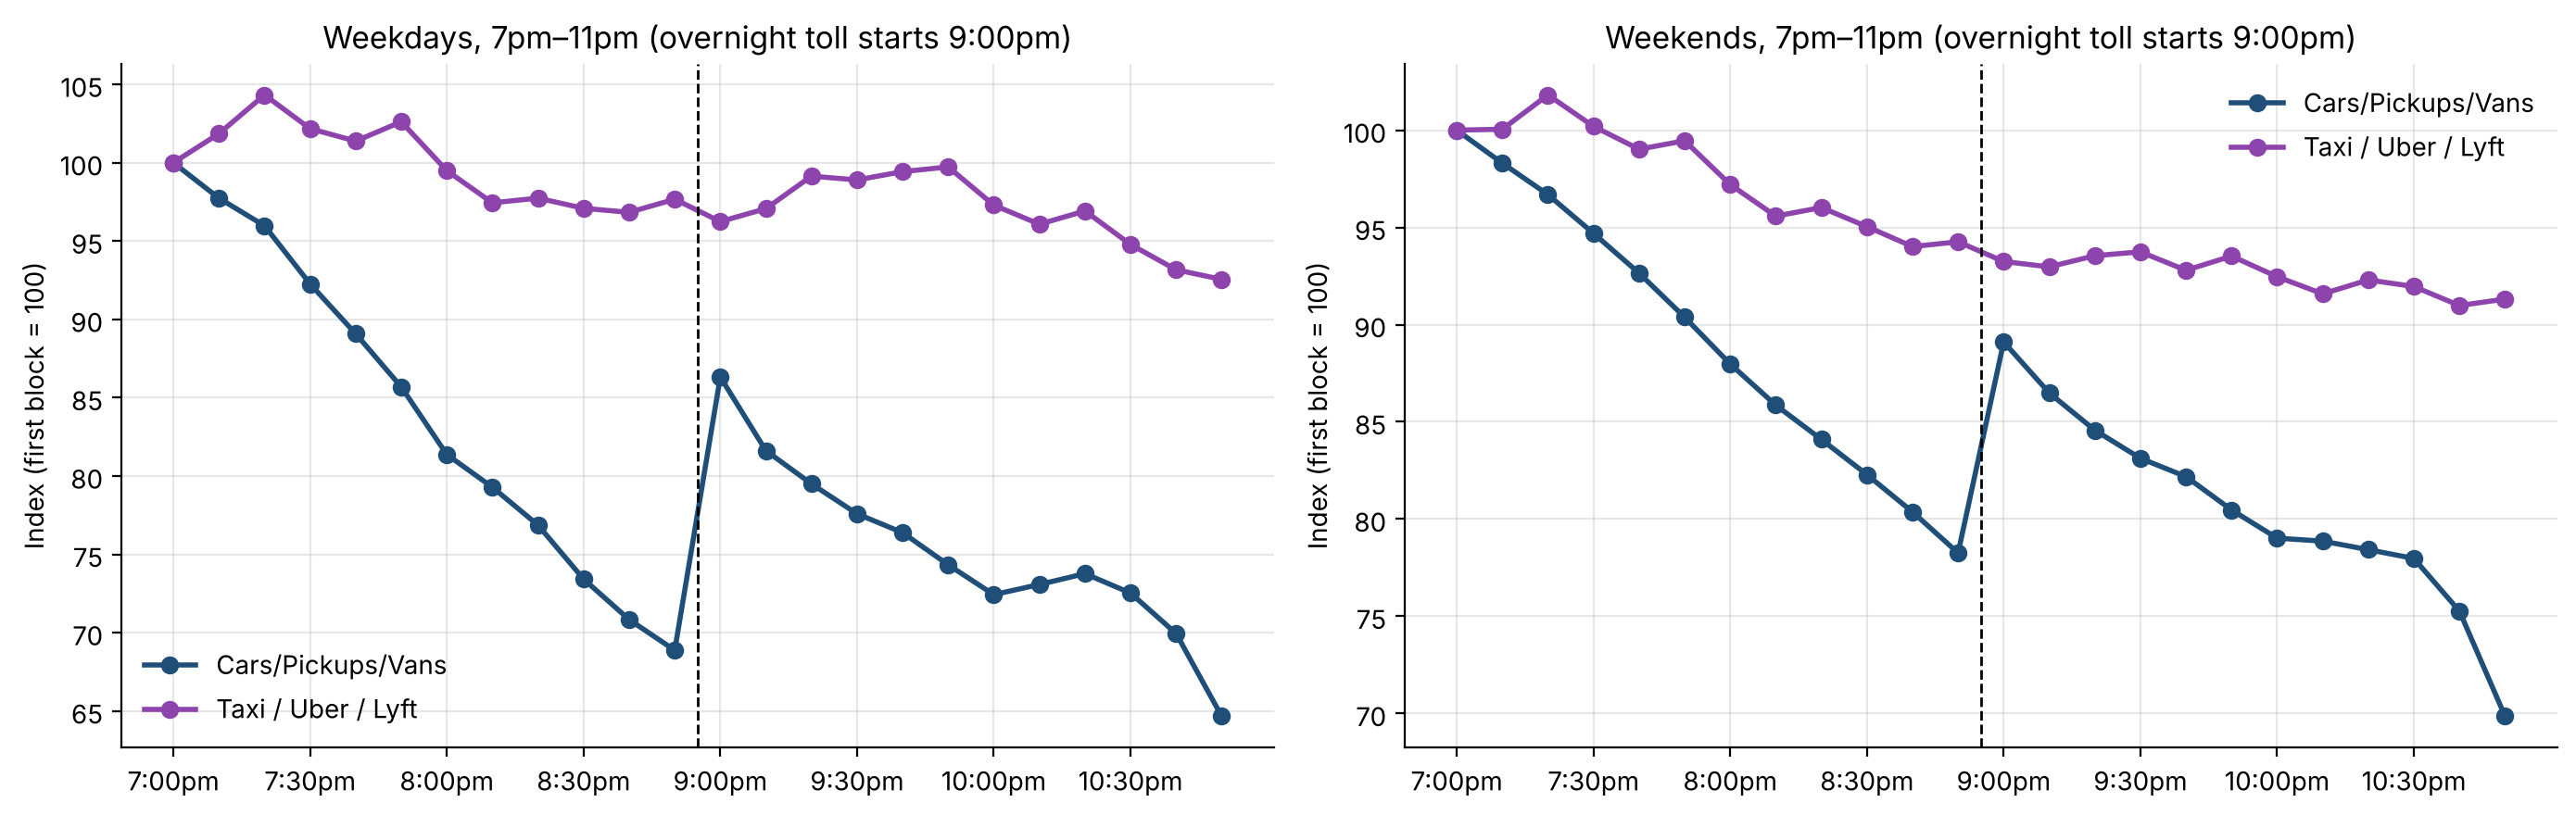

,day_type,vehicle,8:50–8:59pm,9:00–9:09pm,change_%
0,Weekday,Cars/Pickups/Vans,1467,1839,25.3
1,Weekday,Taxi / Uber / Lyft,1734,1709,-1.5
2,Weekend,Cars/Pickups/Vans,1871,2130,13.9
3,Weekend,Taxi / Uber / Lyft,1509,1492,-1.1


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_window(axes[0], "Weekday", 19, 22, 21, "Weekdays, 7pm–11pm (overnight toll starts 9:00pm)")
plot_window(axes[1], "Weekend", 19, 22, 21, "Weekends, 7pm–11pm (overnight toll starts 9:00pm)")
for ax in axes:
    ax.set_xticklabels([f"{(t // 60) - 12}:{t % 60:02d}pm" for t in ax.get_xticks().astype(int)])
plt.tight_layout(); plt.show()

rows = []
for day_type in ["Weekday", "Weekend"]:
    for vehicle in [CAR, TAXI]:
        b, a, chg = boundary_jump(ten_minute, day_type, vehicle, 21)
        rows.append({"day_type": day_type, "vehicle": vehicle,
                     "8:50–8:59pm": round(b), "9:00–9:09pm": round(a), "change_%": round(chg, 1)})
pd.DataFrame(rows)

### Q5: Is toll-timing growing or fading?
We repeat the "cliff" measurements from Q3 and Q4 **separately for 2025 and 2026**. If drivers are learning to game the toll, the cliffs should get bigger. If they're giving up (or paying), the cliffs should shrink.

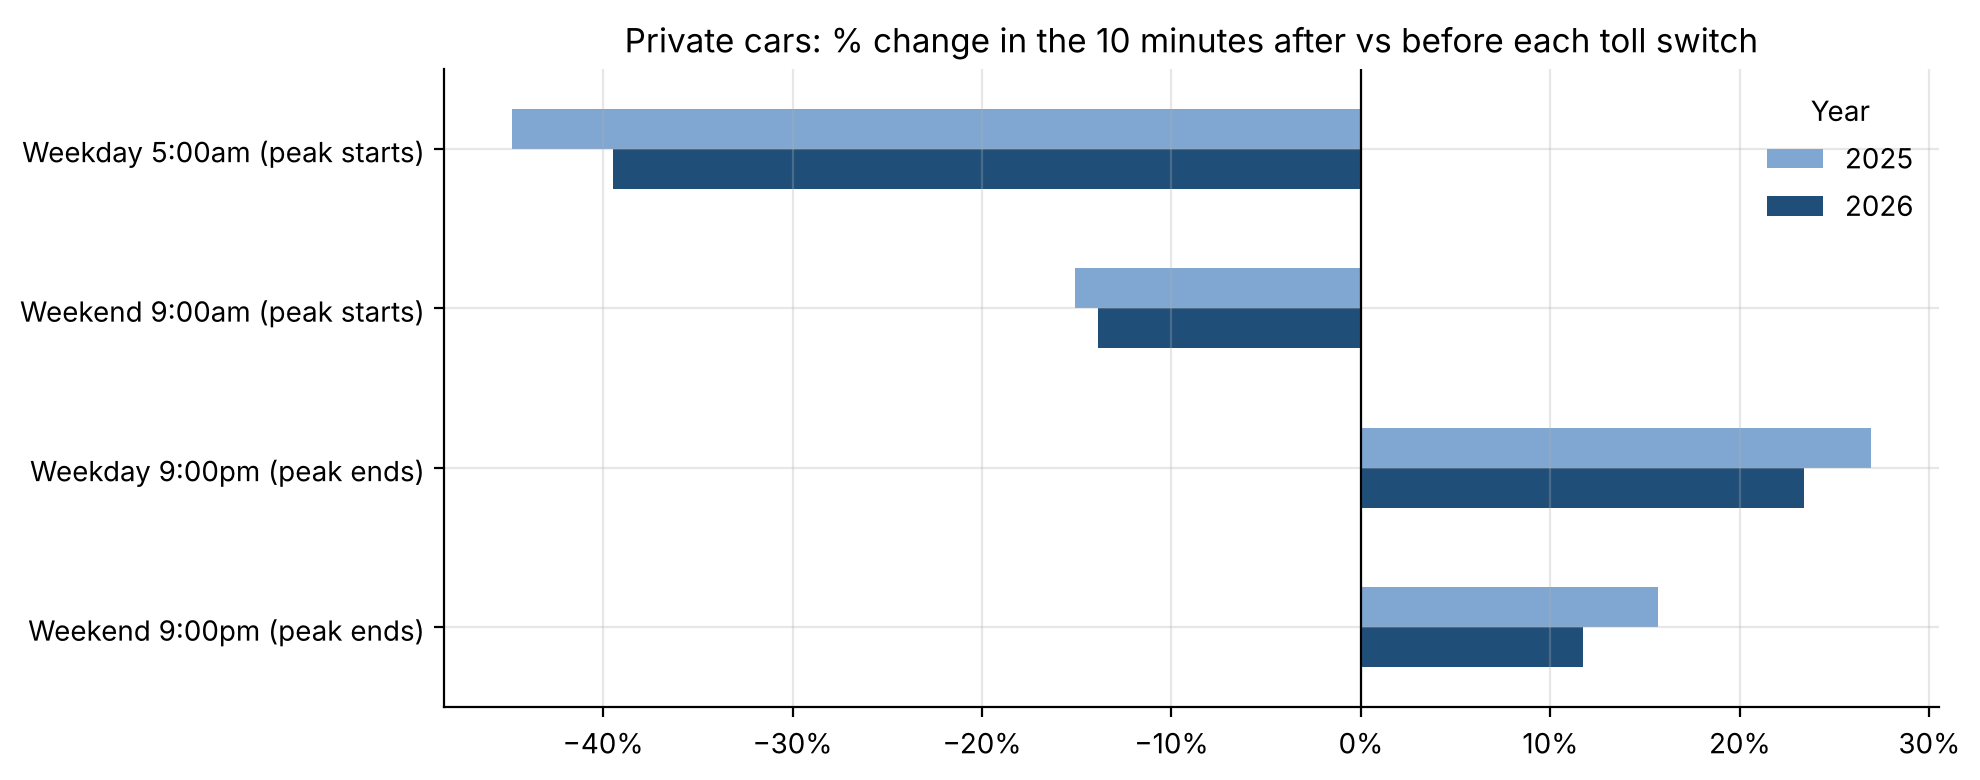

% change from the last 10 minutes before the switch to the first 10 minutes after it


,moment,vehicle,2025,2026
0,Weekday 5:00am (peak starts),Cars/Pickups/Vans,-44.8,-39.5
1,Weekday 5:00am (peak starts),Taxi / Uber / Lyft,3.3,5.4
2,Weekend 9:00am (peak starts),Cars/Pickups/Vans,-15.1,-13.9
3,Weekend 9:00am (peak starts),Taxi / Uber / Lyft,0.7,0.7
4,Weekday 9:00pm (peak ends),Cars/Pickups/Vans,26.9,23.4
5,Weekday 9:00pm (peak ends),Taxi / Uber / Lyft,-1.2,-1.7
6,Weekend 9:00pm (peak ends),Cars/Pickups/Vans,15.7,11.7
7,Weekend 9:00pm (peak ends),Taxi / Uber / Lyft,-1.2,-0.9


In [11]:
def cliff(df, year, day_type, vehicle, boundary_hour):
    sub = df[(df["year"] == year) & (df["day_type"] == day_type) & (df["vehicle"] == vehicle)]
    before = sub[(sub["hour_of_day"] == boundary_hour - 1) & (sub["minute_of_hour"] == 50)]["entries"].sum()
    after = sub[(sub["hour_of_day"] == boundary_hour) & (sub["minute_of_hour"] == 0)]["entries"].sum()
    return (after / before - 1) * 100

moments = [("Weekday", 5, "Weekday 5:00am (peak starts)"),
           ("Weekend", 9, "Weekend 9:00am (peak starts)"),
           ("Weekday", 21, "Weekday 9:00pm (peak ends)"),
           ("Weekend", 21, "Weekend 9:00pm (peak ends)")]
years = sorted(ten_minute["year"].unique())
rows = []
for day_type, hour, label in moments:
    for vehicle in [CAR, TAXI]:
        row = {"moment": label, "vehicle": vehicle}
        for y in years:
            row[str(y)] = round(cliff(ten_minute, y, day_type, vehicle, hour), 1)
        rows.append(row)
cliffs = pd.DataFrame(rows)

# Chart: private cars only, one pair of bars per moment
car_cliffs = cliffs[cliffs["vehicle"] == CAR].set_index("moment")[[str(y) for y in years]]
ax = car_cliffs.plot(kind="barh", figsize=(10, 4), color=["#7fa7d1", CAR_COLOR])
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Private cars: % change in the 10 minutes after vs before each toll switch")
ax.set_ylabel(""); ax.legend(title="Year", frameon=False)
ax.invert_yaxis()
plt.tight_layout(); plt.show()

print("% change from the last 10 minutes before the switch to the first 10 minutes after it")
cliffs

## 5. My Week 2 findings ✍️
*Data from Jan 5, 2025 to Nov 14, 2026. Storm days are excluded from the hourly table.*

1. **The rush moves with the schedule.** On weekdays, the busiest overnight hour before peak is **4am**. On weekends, when peak starts later, the rush moves to **8am**. Same drivers, different toll clock.
2. **Cars vs. taxis:** on weekdays the number of private cars per taxi/Uber/Lyft **doubles from 3am to 4am** (1.0 → 2.0). On weekends it stays low at 4am (0.7) and climbs before 9am instead.
3. **The 5:00am cliff:** private car entries **fall 42.5%** from 4:50 to 5:00am on weekdays. Taxis, which pay the same at any hour, **rise 4.3%**. On weekends the cliff moves to 9:00am: cars **−14.6%**, taxis **+0.7%**.
4. **The 9:00pm jump:** when the cheaper overnight toll starts, private cars **jump 25.3%** on weekdays (8:50 → 9:00pm) and **13.9%** on weekends. Taxis barely move (−1.5% and −1.1%).
5. **Fading a little, still strong:** the weekday 5am cliff was **−44.8% in 2025** and **−39.5% in 2026**. The 9pm jump went from **+26.9%** to **+23.4%**. Drivers still time their trips, slightly less than in year one.

**Bottom line:** thousands of drivers are clearly timing their trips to the toll. They squeeze in just before 5am, or wait until after 9pm, to save money. Taxis show no such pattern.

### Post # 2
> Are New York drivers gaming the congestion toll? I checked the 10-minute data. ⏱️
>
> The $9 peak toll starts at 5:00am. Between 4:50 and 5:00am, private car entries **drop 42%**.
> Taxis and Ubers, which pay the same at any hour? **Up 4%.**
>
> And at 9:00pm, when the toll gets 75% cheaper, private cars **jump 25%** in ten minutes.
>
> The best part: on weekends peak starts at 9am instead of 5am, and the rush **moves with it**.
>
> Drivers are timing their trips to the toll. Slightly less than in 2025, but still clearly. 📉
>
> [chart: 10-minute cars vs taxis around 5am]
>
> Full analysis on GitHub (link in comments).
> #DataScience #NYC #CongestionPricing #Python #DataWithMehreen

## Notes and caveats
- A rush before peak isn't proof of dodging on its own. Early shifts and deliveries also start around then. The **taxi comparison** and the **weekend shift** are what make the case strong.
- Taxis and ride-hail have their own patterns (e.g. airport runs, late-night demand), so they're a useful baseline but not a perfect one.
- The 10-minute table includes storm days and holidays; the hourly table excludes them. Averages over ~95 weeks are barely affected.